In [309]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report


In [310]:
df = pd.read_csv('hotel_bookings.csv')

In [311]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [312]:
df.shape

(119390, 32)

In [313]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [314]:
df.describe(include='object')

C:\Users\noura\AppData\Local\Temp\ipykernel_12248\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [315]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [316]:
# رسومات لتحسين EDA
import matplotlib.pyplot as plt
import seaborn as sns

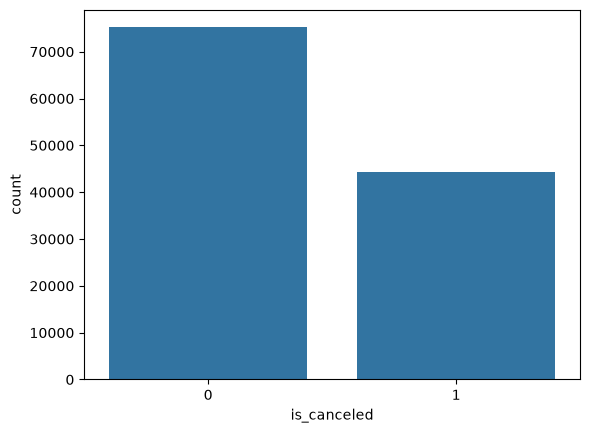

In [317]:
#1. توزيع الحجوزات الملغاة وغير الملغاة
sns.countplot(x='is_canceled', data=df)
plt.show()

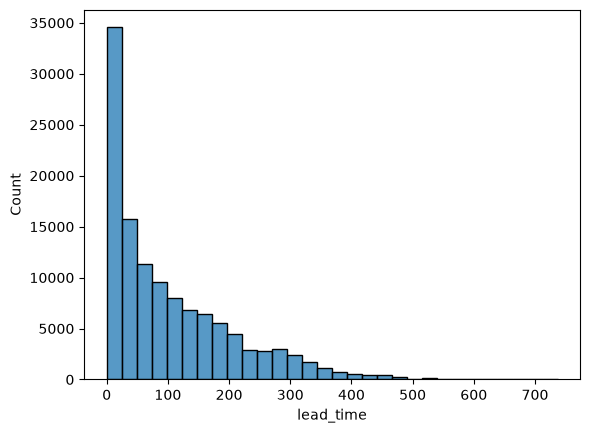

In [318]:
# 2. توزيع lead_time
sns.histplot(df['lead_time'], bins=30)
plt.show()

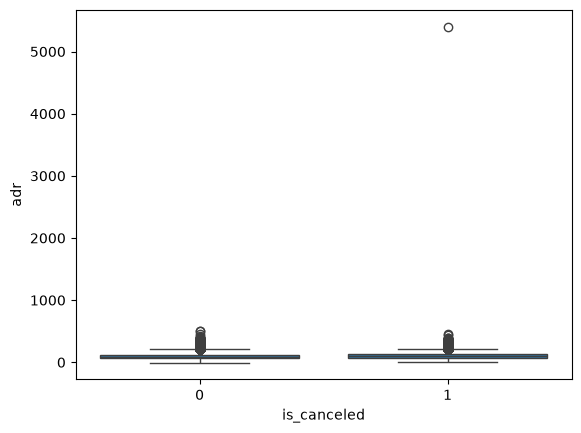

In [319]:
# 3. علاقة adr بحالة الإلغاء
sns.boxplot(x='is_canceled', y='adr', data=df)
plt.show()

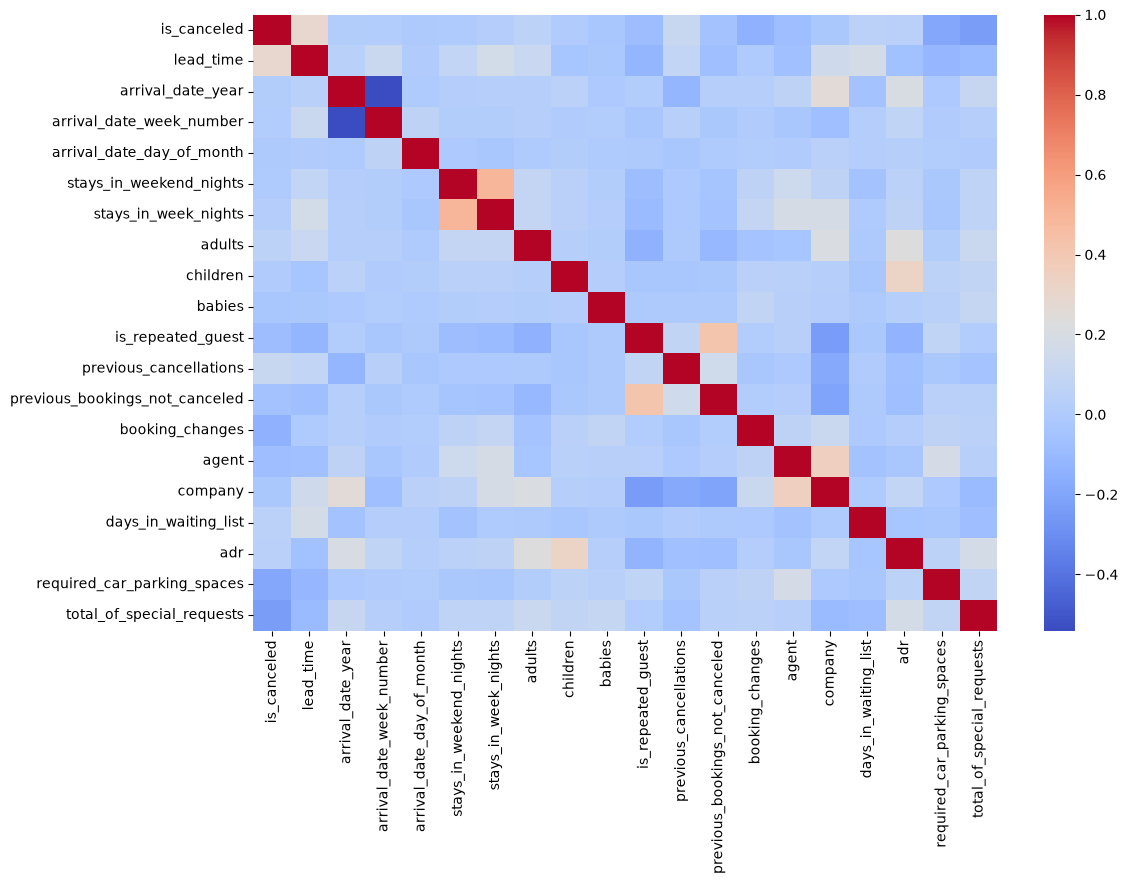

In [320]:
# 4. Correlation Heatmap
corr_matrix = df.select_dtypes(include=['int64', 'float64']).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, cmap='coolwarm')
plt.show()

In [321]:
df["children"].fillna(0,inplace=True)

C:\Users\noura\AppData\Local\Temp\ipykernel_12248\3469679300.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df["children"].fillna(0,inplace=True)


0         0.0
1         0.0
2         0.0
3         0.0
4         0.0
         ... 
119385    0.0
119386    0.0
119387    0.0
119388    0.0
119389    0.0
Name: children, Length: 119390, dtype: float64

In [322]:

df["agent"].fillna(0,inplace=True)


C:\Users\noura\AppData\Local\Temp\ipykernel_12248\1769295532.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df["agent"].fillna(0,inplace=True)


0           0.0
1           0.0
2           0.0
3         304.0
4         240.0
          ...  
119385    394.0
119386      9.0
119387      9.0
119388     89.0
119389      9.0
Name: agent, Length: 119390, dtype: float64

In [323]:
df["company"].fillna(0,inplace=True)


C:\Users\noura\AppData\Local\Temp\ipykernel_12248\1810949900.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df["company"].fillna(0,inplace=True)


0         0.0
1         0.0
2         0.0
3         0.0
4         0.0
         ... 
119385    0.0
119386    0.0
119387    0.0
119388    0.0
119389    0.0
Name: company, Length: 119390, dtype: float64

In [324]:
df["country"].fillna("Unknown",inplace=True)

C:\Users\noura\AppData\Local\Temp\ipykernel_12248\2610528027.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df["country"].fillna("Unknown",inplace=True)


0         PRT
1         PRT
2         GBR
3         GBR
4         GBR
         ... 
119385    BEL
119386    FRA
119387    DEU
119388    GBR
119389    DEU
Name: country, Length: 119390, dtype: str

In [325]:
df.duplicated().sum()

np.int64(31994)

In [326]:
leakage_cols = ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'company']
df.drop(columns=leakage_cols, inplace=True)


C:\Users\noura\AppData\Local\Temp\ipykernel_12248\3816593417.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=leakage_cols, inplace=True)


In [327]:
df['children'] = df['children'].fillna(0)
total_guests = df['adults'] + df['children'] + df['babies']
df = df[(total_guests > 0) & (df['adr'] >= 0)].copy()

In [328]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)


C:\Users\noura\AppData\Local\Temp\ipykernel_12248\2482976261.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)
C:\Users\noura\AppData\Local\Temp\ipykernel_12248\2482976261.py:2: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)


In [329]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['is_family'] = ((df['children'] + df['babies']) > 0).astype(int)
df['had_prev_cancel'] = (df['previous_cancellations'] > 0).astype(int)
df['adr_per_guest'] = df['adr'] / df['total_guests']

In [330]:

df['agent'] = df['agent'].fillna(0).astype(int).astype(str)
X = df.drop(columns=['is_canceled'])
y = df['is_canceled'].values


In [331]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)


In [332]:
cap_cols = ['lead_time', 'adr', 'adr_per_guest', 'total_nights']
for col in cap_cols:
    upper_limit = X_train[col].quantile(0.99)
    X_train[col] = X_train[col].clip(upper=upper_limit)
    X_val[col] = X_val[col].clip(upper=upper_limit)
    X_test[col] = X_test[col].clip(upper=upper_limit)


In [333]:
for dataset in [X_train, X_val, X_test]:
    dataset['lead_time'] = np.log1p(dataset['lead_time'])


In [334]:
top_countries = X_train['country'].value_counts()
common_countries = set(top_countries[top_countries >= 200].index)
for dataset in [X_train, X_val, X_test]:
    dataset['country'] = dataset['country'].fillna('Unknown')
    dataset['country'] = dataset['country'].where(dataset['country'].isin(common_countries), 'Other')


In [335]:
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])


C:\Users\noura\AppData\Local\Temp\ipykernel_12248\407624714.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()


In [336]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Tuned Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestClassifier( n_estimators=500,
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1),
    "LightGBM": LGBMClassifier( n_estimators=300,learning_rate=0.05,random_state=42, verbose=-1)
}

results = []
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    # التقييم على بيانات التحقق (Validation Set) لاختيار الأفضل
    val_preds = pipe.predict(X_val)
    results.append({
        "Model": name,
        "Val Accuracy": accuracy_score(y_val, val_preds),
        "Val Precision": precision_score(y_val, val_preds),
        "Val Recall": recall_score(y_val, val_preds),
        "Val F1-Score": f1_score(y_val, val_preds)
    })

results_df = pd.DataFrame(results).sort_values(by="Val F1-Score", ascending=False)
print("=== مقارنة النماذج على بيانات التحقق (Validation Set) ===")
print(results_df.to_string(index=False))

=== مقارنة النماذج على بيانات التحقق (Validation Set) ===
              Model  Val Accuracy  Val Precision  Val Recall  Val F1-Score
           LightGBM      0.848248       0.751334    0.672569      0.709773
Tuned Decision Tree      0.830257       0.723620    0.622541      0.669285
      Random Forest      0.831808       0.805275    0.514896      0.628150
Logistic Regression      0.814206       0.702863    0.565767      0.626908


In [337]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]

print(f"\nأفضل نموذج تم اختياره: {best_model_name}")
test_preds = best_pipeline.predict(X_test)

print(classification_report(y_test, test_preds))


أفضل نموذج تم اختياره: LightGBM
              precision    recall  f1-score   support

           0       0.88      0.91      0.90      9339
           1       0.75      0.67      0.71      3557

    accuracy                           0.85     12896
   macro avg       0.81      0.79      0.80     12896
weighted avg       0.84      0.85      0.85     12896



In [338]:
os.makedirs('models', exist_ok=True)
joblib.dump(best_pipeline, 'models/hotel_cancellation_model.pkl')

['models/hotel_cancellation_model.pkl']